# 05 · Generating a labelled ML dataset

Learning-based wavefront sensing, turbulence-strength estimation and channel prediction all need many
realistic received fields with known ground truth. `generate_dataset` sweeps channel parameters, draws several
independent realizations per sweep point, and stores each one as a sample with physical labels (README §7):

- **per sample:** the swept parameters, the seed, the measured r₀, mean coupling efficiency and scintillation;
- **per frame:** fiber coupling efficiency `eta`, scintillation index `scint`, angle of arrival `tilt`.

Every sample can be regenerated from the manifest (base seed + sweep point + realization), and re-running the
same call resumes an interrupted dataset.

> **About the outputs.** The results stored in this notebook were produced on an NVIDIA GeForce RTX 4080
> (16 GiB) under Windows. Timings, and the run mode the memory guard picks, depend on the GPU; the statistics
> do not. Open the notebook in Jupyter or VS Code with the OPAL environment as the kernel and run the cells in
> order. The first cell moves to the repository root, so every path below is relative to it.

In [1]:
import os
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")      # hide TensorFlow's C++ start-up messages
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "configs").is_dir())
os.chdir(ROOT)                                           # paths below are relative to the repository root

import time
import numpy as np
import matplotlib.pyplot as plt
import opal

%matplotlib inline
plt.rcParams.update({"figure.dpi": 80, "image.origin": "lower"})
print("OPAL", opal.__version__)

OPAL 1.1.0


## 1. Generate

3 r₀ values × 2 wind speeds × 4 realizations = 24 samples. Each sample is 40 ticks, of which every 4th is kept
(10 frames), centre-cropped to 128² (the labels are computed on the full grid before cropping).

In [2]:
DS = "runs/dataset"
manifest = opal.generate_dataset(
    "configs/quickstart_256.json", DS,
    sweep=["r0=0.05:0.15:3", "wind=5,15"],
    realizations=4,
    num_steps=40, stride=4, crop=128,
    targets=("intensity", "phase"),
    seed=2026,
    label_aperture=0.3,
)
print(f"\nstatus {manifest['status']}: {manifest['num_samples']} samples, sweep {manifest['sweep']}, "
      f"base seed {manifest['base_seed']}")
print("files:", sorted(p.name for p in Path(DS).iterdir()), "+", len(list(Path(DS, "samples").iterdir())), "samples")

[opal    0.00s] dataset: 6 sweep points x 4 realizations = 24 samples, 40 ticks (stride 4, 10 frames), targets intensity, phase
[opal    0.00s] building simulator: N=256, 10 layers


[opal    7.32s] built simulator in 7.3 s (reused for every realization of this sweep point via reseed)


[opal   19.05s] sample 1/24 [r0=0.05, wind=5] seed 580060173: 11.66 s | r0 0.052 m | eta 0.006 | SI 0.159


[opal   26.37s] sample 2/24 [r0=0.05, wind=5] seed 108373515: 6.62 s | r0 0.050 m | eta 0.017 | SI 0.147


[opal   37.56s] sample 3/24 [r0=0.05, wind=5] seed 1000890113: 10.46 s | r0 0.050 m | eta 0.097 | SI 0.182


...

[opal  247.01s] built simulator in 5.0 s (reused for every realization of this sweep point via reseed)


[opal  258.78s] sample 21/24 [r0=0.15, wind=15] seed 109332423: 11.71 s | r0 0.154 m | eta 0.200 | SI 0.105


[opal  269.48s] sample 22/24 [r0=0.15, wind=15] seed 1925896384: 9.98 s | r0 0.148 m | eta 0.281 | SI 0.129


[opal  283.37s] sample 23/24 [r0=0.15, wind=15] seed 86100950: 13.10 s | r0 0.157 m | eta 0.221 | SI 0.130


[opal  294.26s] sample 24/24 [r0=0.15, wind=15] seed 1882587875: 10.16 s | r0 0.148 m | eta 0.359 | SI 0.112
[opal  294.45s] done: 24 samples in 294.4 s (GPU simulation 238.8 s) -> runs\dataset

status complete: 24 samples, sweep {'r0': [0.05, 0.1, 0.15], 'wind': [5.0, 15.0]}, base seed 2026
files: ['labels.csv', 'manifest.json', 'samples'] + 24 samples


In [3]:
from opal.dataset import load_labels, load_sample

labels = load_labels(DS)
print("columns:", ", ".join(labels[0]), "\n")
print("sample  r0 (m)  wind (m/s)  realization  seed        r0 measured  eta mean  scint mean")
for row in labels:
    print(f"{row['sample']:6d} {row['r0']:7.3f} {row['wind']:11.0f} {row['realization']:12d}  {row['seed']:<11d}"
          f"{row['r0_measured']:11.3f} {row['eta_mean']:9.3f} {row['scint_mean']:11.3f}")

columns: sample, file, point, realization, seed, sweep_r0, sweep_wind, r0, wind, zenith, layers, N, dx, wavelength, L0, dt, orbit, elevation, frames, stride, crop, label_aperture_m, D_over_r0, r0_measured, eta_mean, eta_std, scint_mean, tilt_rms_rad, sim_time_s 

sample  r0 (m)  wind (m/s)  realization  seed        r0 measured  eta mean  scint mean
     0   0.050           5            0  580060173        0.052     0.006       0.159
     1   0.050           5            1  108373515        0.050     0.017       0.147
     2   0.050           5            2  1000890113       0.050     0.097       0.182
     3   0.050           5            3  1858464651       0.051     0.073       0.154
     4   0.050          15            0  203843975        0.047     0.026       0.206
     5   0.050          15            1  1294286227       0.050     0.008       0.197
     6   0.050          15            2  1857319346       0.051     0.034       0.189
     7   0.050          15            3  709472

## 2. What the samples look like

First frame of realization 0 at each r₀ (wind 5 m/s). Smaller r₀ means stronger turbulence: finer phase
structure and deeper fades.

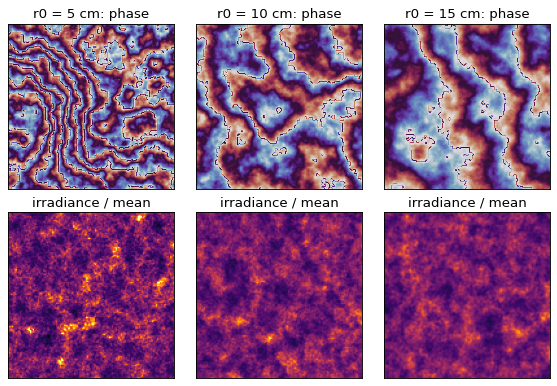

one sample: {'steps': (10,), 'eta': (10,), 'scint': (10,), 'tilt': (10, 2), 'intensity': (10, 128, 128), 'phase': (10, 128, 128)}


In [4]:
picks = [row for row in labels if row["wind"] == 5 and row["realization"] == 0]
fig, axes = plt.subplots(2, len(picks), figsize=(2.4 * len(picks), 4.9))
for col, row in enumerate(picks):
    s = load_sample(DS, row["sample"])
    axes[0, col].imshow(s["phase"][0], cmap="twilight", vmin=-np.pi, vmax=np.pi)
    axes[0, col].set_title(f"r0 = {row['r0'] * 100:.0f} cm: phase")
    axes[1, col].imshow(s["intensity"][0] / s["intensity"][0].mean(), cmap="inferno", vmin=0, vmax=3)
    axes[1, col].set_title("irradiance / mean")
for ax in axes.flat:
    ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout()
plt.show()
print("one sample:", {k: v.shape for k, v in s.items() if k != "labels"})

## 3. The labels follow the physics

Mean coupling efficiency against the von Kármán prediction for the 0.3 m label aperture, and the scintillation
index, for every sample. The spread between realizations is the natural variability a model has to cope with.

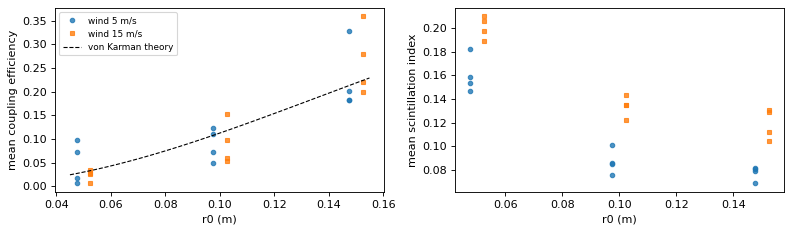

In [5]:
from opal.analysis import coupling_efficiency_theoretical_vk

r0 = np.array([row["r0"] for row in labels])
wind = np.array([row["wind"] for row in labels])
grid = np.linspace(0.045, 0.155, 50)

fig, axes = plt.subplots(1, 2, figsize=(10, 3))
for w, marker in ((5, "o"), (15, "s")):
    m = wind == w
    jitter = (w - 10) / 2000
    axes[0].plot(r0[m] + jitter, [row["eta_mean"] for row, k in zip(labels, m) if k], marker, ms=4,
                 alpha=0.8, label=f"wind {w} m/s")
    axes[1].plot(r0[m] + jitter, [row["scint_mean"] for row, k in zip(labels, m) if k], marker, ms=4, alpha=0.8)
axes[0].plot(grid, [coupling_efficiency_theoretical_vk(0.3, r, 25.0) for r in grid], "k--", lw=1,
             label="von Karman theory")
axes[0].set(xlabel="r0 (m)", ylabel="mean coupling efficiency")
axes[0].legend(fontsize=8)
axes[1].set(xlabel="r0 (m)", ylabel="mean scintillation index")
plt.tight_layout()
plt.show()

## 4. Loading it for training

Three ways in, from simplest to most scalable:

In [6]:
X, y = opal.load_dataset(DS, target="phase", label_keys=("r0", "eta_mean"))   # everything in memory
print("load_dataset:", X.shape, X.dtype, "labels", y.shape)

n = sum(1 for _ in opal.iter_samples(DS))                                        # one sample at a time
print("iter_samples:", n, "samples")

tfds = opal.as_tf_dataset(DS, target="intensity", label_keys=("eta",), per_frame=True)   # tf.data stream
x0, y0 = next(iter(tfds))
print("as_tf_dataset (per frame):", x0.shape, x0.dtype, "label eta =", y0.numpy())

load_dataset: (24, 10, 128, 128) float32 labels (24, 2)
iter_samples: 24 samples
as_tf_dataset (per frame): (128, 128) <dtype: 'float32'> label eta = [0.00165252]


## 5. Optional: a small CNN that reads r₀ off the phase

Set `TRAIN = True` to fit a tiny convolutional network that predicts r₀ from a single phase frame. The split is
by sample, not by frame, because frames of one sample are correlated. This dataset is deliberately small; for
real work generate more realizations and sweep points.

In [7]:
TRAIN = False

if TRAIN:
    import tensorflow as tf

    X, y = opal.load_dataset(DS, target="phase", label_keys=("r0",))          # X [S, F, n, n]
    order = np.random.default_rng(0).permutation(len(X))
    split = int(0.75 * len(X))
    train, test = order[:split], order[split:]

    def frames_of(idx):
        p = X[idx].reshape(-1, *X.shape[2:])                                # every frame is an image
        x = np.stack([np.cos(p), np.sin(p)], axis=-1)                      # wrapped phase without 2*pi jumps
        return x.astype(np.float32), np.repeat(y[idx], X.shape[1], axis=0)

    (x_tr, y_tr), (x_te, y_te) = frames_of(train), frames_of(test)
    tf.keras.utils.set_random_seed(0)
    model = tf.keras.Sequential([
        tf.keras.layers.Input(x_tr.shape[1:]),
        tf.keras.layers.Conv2D(16, 3, activation="relu"),
        tf.keras.layers.MaxPooling2D(2),
        tf.keras.layers.Conv2D(32, 3, activation="relu"),
        tf.keras.layers.MaxPooling2D(2),
        tf.keras.layers.Conv2D(32, 3, activation="relu"),
        tf.keras.layers.GlobalAveragePooling2D(),
        tf.keras.layers.Dense(32, activation="relu"),
        tf.keras.layers.Dense(1),
    ])
    model.compile(optimizer=tf.keras.optimizers.Adam(2e-3), loss="mse")
    model.fit(x_tr, y_tr, epochs=30, batch_size=16, verbose=0, validation_data=(x_te, y_te))
    pred = model.predict(x_te, verbose=0).ravel()
    print(f"held-out r0 error: {np.mean(np.abs(pred - y_te[:, 0])) * 100:.2f} cm "
          f"(always predicting the mean: {np.mean(np.abs(y_te[:, 0] - y_tr.mean())) * 100:.2f} cm)")
    for value in np.unique(y_te[:, 0]):
        m = y_te[:, 0] == value
        print(f"  true r0 {value:.3f} m -> predicted {pred[m].mean():.3f} +- {pred[m].std():.3f} m")
else:
    print("TRAIN = False: set it to True and re-run this cell to train the example model.")

TRAIN = False: set it to True and re-run this cell to train the example model.


## CLI equivalent

```bash
opal dataset -c configs/quickstart_256.json -o runs/dataset --sweep r0=0.05:0.15:3 --sweep wind=5,15 \
    -k 4 --steps 40 --stride 4 --crop 128 --seed 2026 --label-aperture 0.3
opal view runs/dataset --sample 3          # browse a sample with its per-frame labels
```